# TESTING SPATIAL TRACKING 
Assumed B = 3000 G. 
Assumed a step change in Delta xperp = difference * cos(random angle).
Ignored details of gyroangle and any information on exactly where on the perpendicular plane. one coordinate for position.

In [52]:
import parameters as p
import auxiliary_funcs as af 
import collisions_vec as col
import wave_particle_vec as wpi
import monte_carlo_vec as mc

import matplotlib.pyplot as plt
import numpy as np

In [53]:
def _reflect_velocity_boundaries(v_new): # intermediate, process new velocities to be in boundaries
    v_new = np.asarray(v_new, dtype=float)

    v_new[..., 0] = np.abs(v_new[..., 0])

    xi = v_new[..., 1]
    xi = ((xi + 1) % 4) - 1 # map to periodic domain of length 4 centered at 0
    xi = np.where(xi > 1, 2 - xi, xi) # reflect into [-1,1]

    v_new[..., 1] = xi
    return v_new


def singlestep_mc(v_current, x_current, D_func, A_func, dt, R, Phi): # single step of N particles
    v_current = np.asarray(v_current, dtype=float) # (N, 2)
    x_current = np.asarray(x_current, dtype=float) # (N, 1) for now
    if v_current.ndim == 1:  # single particle, original shape (2,0) as [x, xi]
        v_current = v_current.reshape(1, 2)

    D_loc = np.asarray(D_func(v_current), dtype=float) # loc for local # (N, 2, 2)
    A_loc = np.asarray(A_func(v_current), dtype=float) # (N, 2)

    std = np.sqrt(2 * np.stack([D_loc[..., 0, 0], D_loc[..., 1, 1]], axis=-1) * dt) # recall D is diagonal
    dv_D = std * np.random.standard_normal(size=v_current.shape) # N(0, std^2) ~ std * N(0,1)
    dv_A = A_loc * dt

    v_new = v_current + dv_D + dv_A
    v_new = _reflect_velocity_boundaries(v_new)
    delta_vperp = v_new[:,0] * np.sqrt(1-v_new[:,1]**2) - v_current[:,0] * np.sqrt(1-v_current[:,1]**2)
    gyro_random = np.random.uniform(0, 2*np.pi, size=x_current.shape)
    x_new = (delta_vperp * np.cos(gyro_random))/p.OMEGA_ALPHA

    lc_condition = np.sqrt(1 - (1 - Phi / v_new[..., 0]**2) / R) - np.abs(v_new[..., 1])
    escape = lc_condition < 0 # boolean array

    if v_current.ndim == 1:
        x_new = (v_new[0] * np.sqrt(1-v_new[1]**2) - v_current[0] * np.sqrt(1-v_current[1]**2))/p.OMEGA_ALPHA
        return v_new[0], x_new, bool(escape[0]) # returning [x_new, xi_new], T/F

    return v_new, x_new, escape

# Testing Collision Tracking of a Single Particle

In [45]:
DT = 1e-5 
NUMSTEPS = int(1e7)
R=5
# PHI=0.01
PHI = 1000000 # ignore the loss cone
print(singlestep_mc([[1,1]], [0], D_func=col.D_xxi, A_func=col.A_xxi, dt=DT, R=R, Phi=PHI))


(array([[1.00022415, 0.99999967]]), array([2.79811186e-12]), array([False]))


In [46]:
velocities, positions = np.empty((NUMSTEPS,2)), np.empty(NUMSTEPS)
v_current = np.array([1,0])
x_current=np.array([0])

for step in range(NUMSTEPS): 
    v_new, x_new, escape = singlestep_mc(v_current, x_current, D_func=col.D_xxi, A_func=col.A_xxi, dt=DT, R=R, Phi=PHI) 
    velocities[step] = (v_new[0,:])
    positions[step] = (x_new[0])
    v_current = v_new
    x_current = x_new
    if step % 10000 == 0: 
        print(step)

velocities = np.asarray(velocities)
positions = np.asarray(positions)

0
10000
20000
30000
40000
50000
60000
70000
80000
90000
100000
110000
120000
130000
140000
150000
160000
170000
180000
190000
200000
210000
220000
230000
240000
250000
260000
270000
280000
290000
300000
310000
320000
330000
340000
350000
360000
370000
380000
390000
400000
410000
420000
430000
440000
450000
460000
470000
480000
490000
500000
510000
520000
530000
540000
550000
560000
570000
580000
590000
600000
610000
620000
630000
640000
650000
660000
670000
680000
690000
700000
710000
720000
730000
740000
750000
760000
770000
780000
790000
800000
810000
820000
830000
840000
850000
860000
870000
880000
890000
900000
910000
920000
930000
940000
950000
960000
970000
980000
990000
1000000
1010000
1020000
1030000
1040000
1050000
1060000
1070000
1080000
1090000
1100000
1110000
1120000
1130000
1140000
1150000
1160000
1170000
1180000
1190000
1200000
1210000
1220000
1230000
1240000
1250000
1260000
1270000
1280000
1290000
1300000
1310000
1320000
1330000
1340000
1350000
1360000
1370000
1380000
13

In [47]:
print(velocities.shape)
print(positions.shape)

(10000000, 2)
(10000000,)


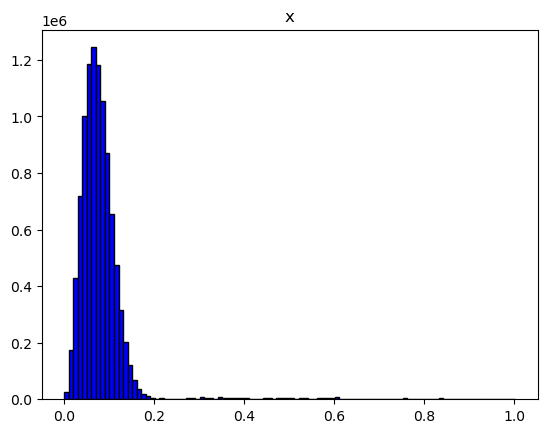

In [48]:
plt.hist(velocities[:, 0], bins=100, color='blue', edgecolor='black')
plt.title('x')
plt.show()

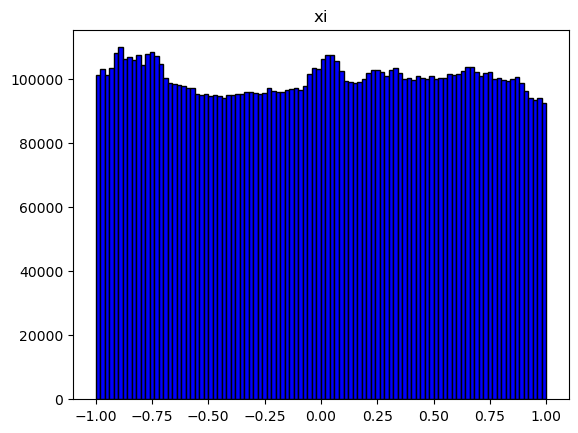

In [49]:
plt.hist(velocities[:, 1], bins=100, color='blue', edgecolor='black')
plt.title('xi')
plt.show()

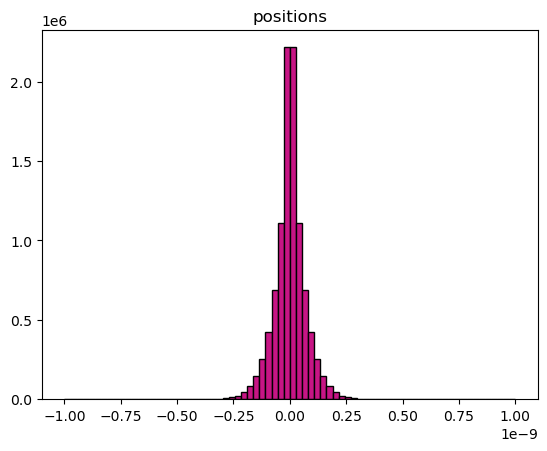

In [50]:
# plot for one particle kicked around, what does its distrivution look like? hopefully something that is gaussian? 
plt.hist(positions[:], bins=np.linspace(-10**(-9), 10**(-9), 75), color='mediumvioletred', edgecolor='black')
plt.title('positions')
plt.show()

# Testing Karney Tracking of a Single Particle


In [292]:
DT = 1e-4
NUMSTEPS = int(1e6)
R=5
# PHI=0.01
PHI = 1000000 # ignore the loss cone
E_0 = 1 
KPERP = 1e-9 
OMEGA = 1

D_karney = lambda v_current: wpi.D_karney(v_current, omega=OMEGA, E_0=E_0, k_perp=KPERP)
A_karney = lambda v_current: wpi.A_karney(v_current, omega=OMEGA, E_0=E_0, k_perp=KPERP)


print(singlestep_mc([[1,0.5]], [0], D_func=D_karney, A_func=A_karney, dt=DT, R=R, Phi=PHI))

(array([[0.99694305, 0.49794598]]), array([1.46846367e-11]), array([False]))


In [312]:
velocities, positions = np.empty((NUMSTEPS,2)), np.empty(NUMSTEPS)
v_current = np.array([5,0.5])
x_current=np.array([0])

for step in range(NUMSTEPS): 
    v_new, x_new, escape = singlestep_mc(v_current, x_current, D_func=D_karney, A_func=A_karney, dt=DT, R=R, Phi=PHI) 
    velocities[step] = (v_new[0,:])
    positions[step] = (x_new[0])
    v_current = v_new
    x_current = x_new
    if step % 10000 == 0: 
        print(step)

velocities = np.asarray(velocities)
positions = np.asarray(positions)

0
10000
20000
30000
40000
50000
60000
70000
80000
90000
100000
110000
120000
130000
140000
150000
160000
170000
180000
190000
200000
210000
220000
230000
240000
250000
260000
270000
280000
290000
300000
310000
320000
330000
340000
350000
360000
370000
380000
390000
400000
410000
420000
430000
440000
450000
460000
470000
480000
490000
500000
510000
520000
530000
540000
550000
560000
570000
580000
590000
600000
610000
620000
630000
640000
650000
660000
670000
680000
690000
700000
710000
720000
730000
740000
750000
760000
770000
780000
790000
800000
810000
820000
830000
840000
850000
860000
870000
880000
890000
900000
910000
920000
930000
940000
950000
960000
970000
980000
990000


/var/folders/5l/cp2w2dsj569686mqpbzbm61c0000gn/T/ipykernel_84857/2151035625.py:12: RuntimeWarning: invalid value encountered in sqrt
  resonance = np.sqrt(1 - OMEGA**2 / KPERP**2 / p.V_TH_A**2 / x_line**2)


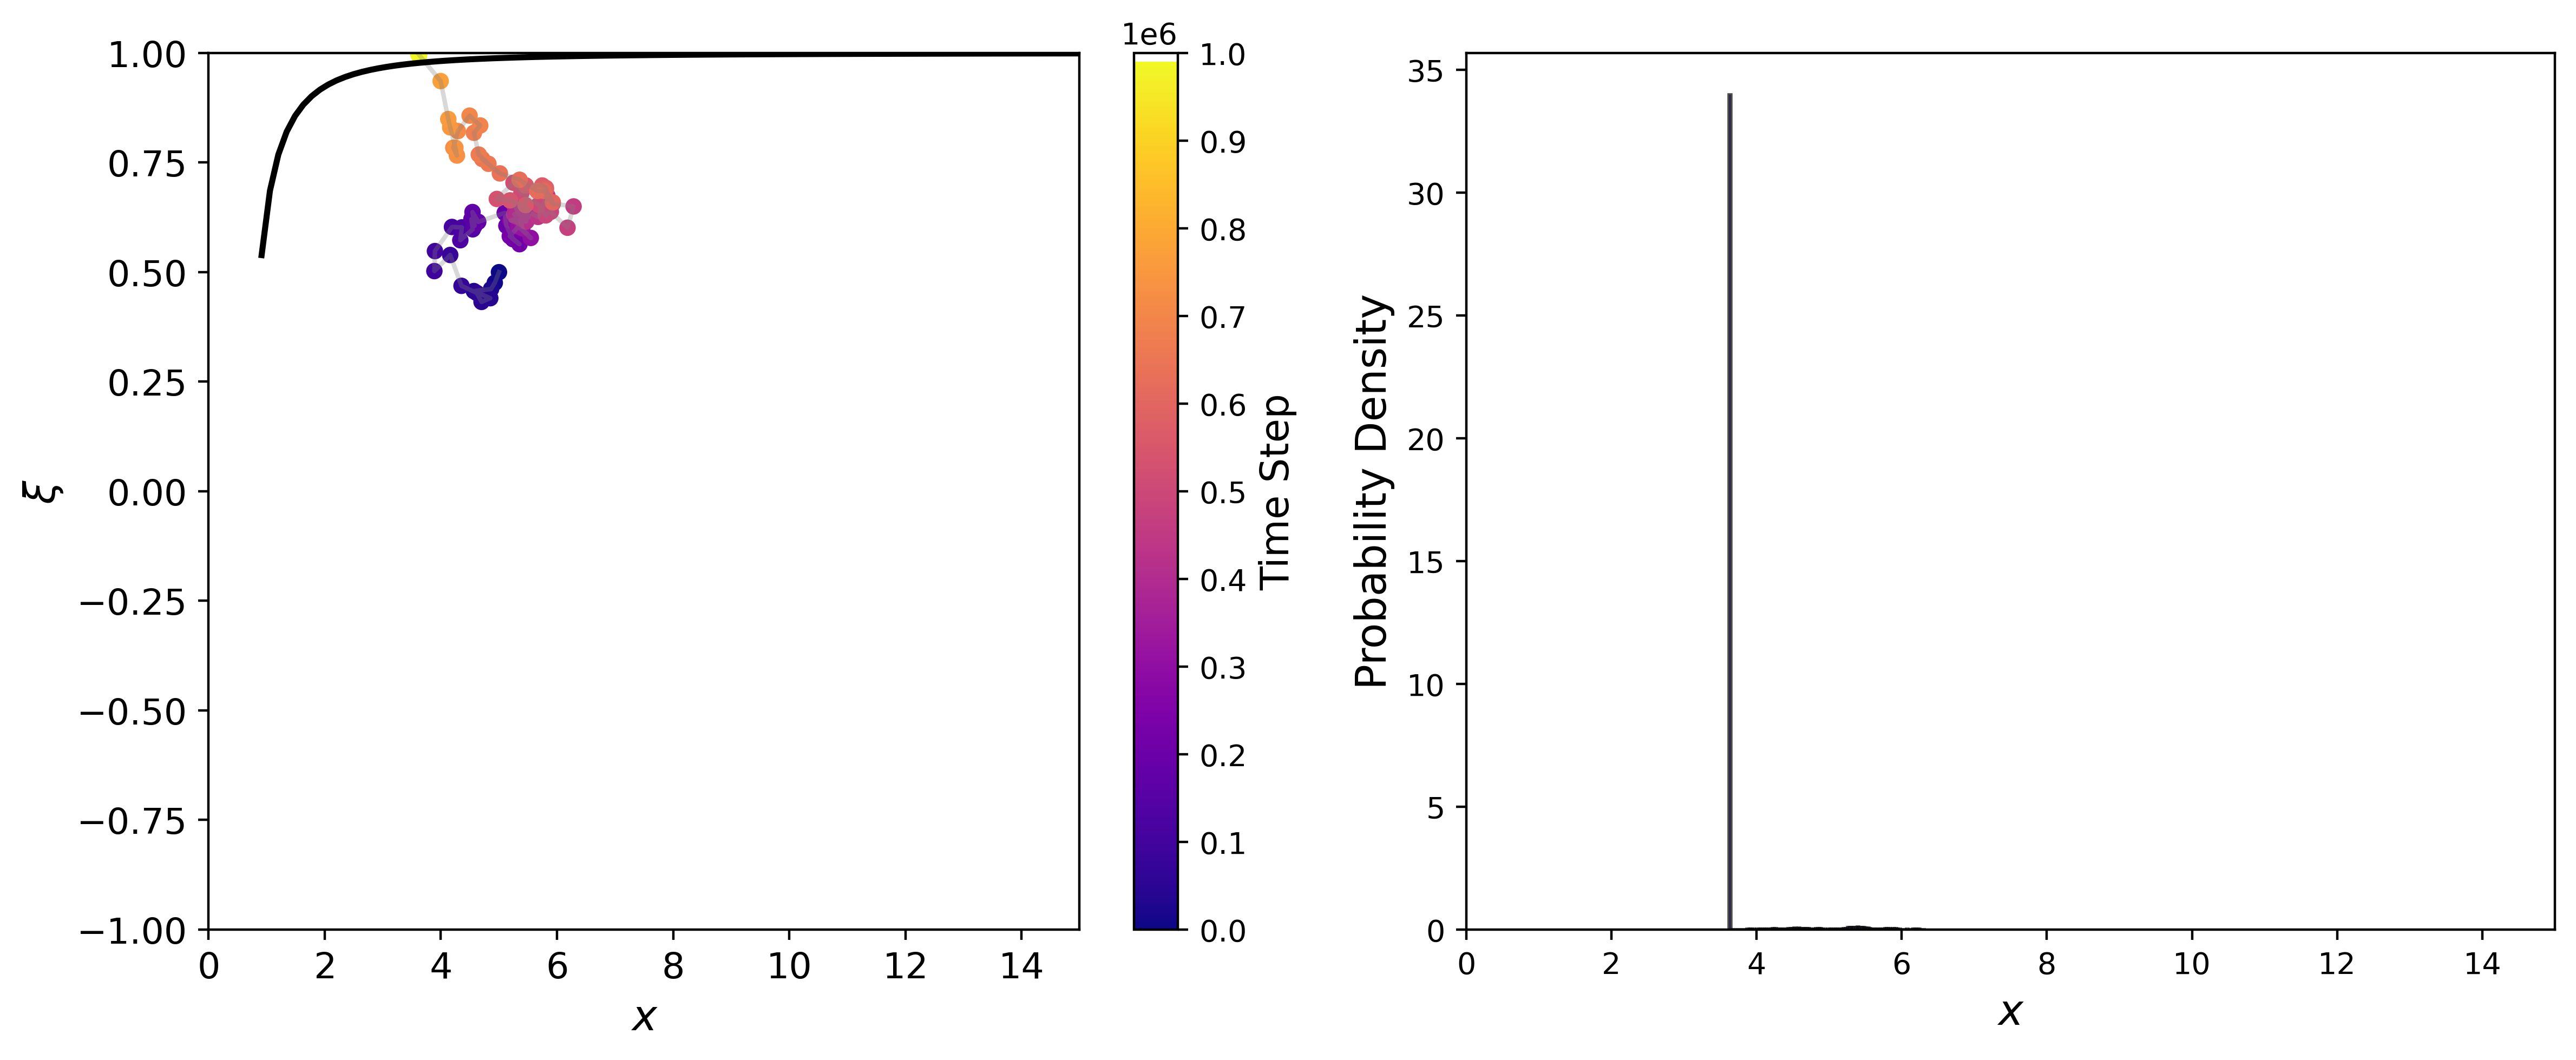

In [316]:
cutoff = 100000
x = velocities[:cutoff:1000, 0]
y = velocities[:cutoff:1000, 1]
t = np.arange(len(x))

colors = t * (NUMSTEPS / len(t))

x_values = velocities[:, 0]
xmax = 15
x_line = np.linspace(OMEGA / KPERP / p.V_TH_A, xmax, 100)

resonance = np.sqrt(1 - OMEGA**2 / KPERP**2 / p.V_TH_A**2 / x_line**2)

fig, axs = plt.subplots(1, 2, figsize=(12, 5), dpi=400)

scatter = axs[0].scatter(x, y, c=colors, cmap='plasma', s=20)
axs[0].plot(x, y, color='gray', alpha=0.3)
axs[0].set_xlabel(r'$x$', fontsize=14)
axs[0].set_ylabel(r'$\xi$', fontsize=14)
axs[0].tick_params(axis='both', labelsize=12)
axs[0].set_ylim(-1,1)
axs[0].set_xlim(0,xmax)
axs[0].plot(x_line,resonance,linewidth=2, color='black')

cbar = fig.colorbar(scatter, ax=axs[0])
ticks = np.arange(0, NUMSTEPS+1, NUMSTEPS/10)
cbar.ax.tick_params(labelsize=10) 
cbar.set_ticks(ticks)
cbar.set_label('Time Step', fontsize=13)

axs[1].hist(x_values, bins=100, density=True, alpha=0.7,
            color='mediumslateblue', edgecolor='black')
# axs[1].plot(x_line,
#             4 / np.sqrt(np.pi) * x_line**2 * np.exp(-x_line**2),
#             color='red')
axs[1].set_xlabel(r'$x$', fontsize=14)
axs[1].set_ylabel('Probability Density', fontsize=14)
axs[1].set_xlim(0, xmax)

plt.tight_layout()
plt.show()

In [311]:
print(resonance)

[       nan 0.53855134 0.68557696 0.76767008 0.82002532 0.85595782
 0.88186457 0.90123363 0.91613003 0.92785104 0.93724958 0.94490721
 0.95123253 0.95651997 0.96098632 0.96479422 0.96806771 0.97090282
 0.97337481 0.9755434  0.97745647 0.97915279 0.980664   0.98201617
 0.98323093 0.98432632 0.98531754 0.9862174  0.98703683 0.98778515
 0.98847037 0.98909941 0.98967826 0.99021212 0.99070554 0.99116252
 0.99158656 0.99198076 0.99234785 0.99269028 0.99301019 0.99330954
 0.99359003 0.99385324 0.99410054 0.9943332  0.99455235 0.99475901
 0.99495413 0.99513854 0.99531302 0.99547826 0.99563491 0.99578355
 0.99592472 0.99605892 0.99618659 0.99630815 0.99642399 0.99653445
 0.99663987 0.99674056 0.99683678 0.9969288  0.99701686 0.99710118
 0.99718198 0.99725944 0.99733376 0.99740509 0.99747359 0.99753941
 0.9976027  0.99766357 0.99772215 0.99777856 0.9978329  0.99788526
 0.99793575 0.99798445 0.99803145 0.99807682 0.99812064 0.99816299
 0.99820391 0.99824348 0.99828176 0.9983188  0.99835465 0.9983